In [1]:
import pandas as pd

df = pd.read_csv("sales_data.csv")
df.shape

(1030, 14)

In [2]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


In [3]:
df.iloc[0]        # 0번 줄을 세로로

order_date         2023-01-01
shipping_date      2023-01-04
delivery_date      2023-01-03
region                     부산
category                 전자제품
product_id               2772
quantity                   61
unit_price           34977.69
customer_id               327
customer_age             67.0
customer_gender             M
satisfaction              1.0
status                    배송중
total_sales        2133639.09
Name: 0, dtype: object

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   str    
 1   shipping_date    1030 non-null   str    
 2   delivery_date    1025 non-null   str    
 3   region           1030 non-null   str    
 4   category         1030 non-null   str    
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   str    
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   str    
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), str(7)
memory usage: 112.8 KB


In [5]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


### [실습 2] 완전성 검사

In [6]:
df.isnull().sum()            # 칸마다 빈 곳의 수

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

In [7]:
(df.isnull().sum() / len(df) * 100).round(1)   # 비율(%)

order_date         0.0
shipping_date      0.0
delivery_date      0.5
region             0.0
category           0.0
product_id         0.0
quantity           0.0
unit_price         0.0
customer_id        0.0
customer_age       5.0
customer_gender    0.0
satisfaction       2.9
status             0.0
total_sales        0.0
dtype: float64

### [실습 2] 일관성 검사

In [8]:
print(df.duplicated().sum())      # 완전히 같은 줄의 수

26


In [9]:
df[df.duplicated(keep=False)].sort_values("order_date").head(4)

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
63,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1029,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1001,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34
128,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34


### [실습 2] 정확성 검사

In [10]:
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print((diff > 1).sum())           # 금액 != 수량 x 단가
cols = ["quantity", "unit_price", "total_sales"]
df.loc[diff > 1, cols].head(3)

22


,quantity,unit_price,total_sales
31,528,235225.85,22346455.75
188,943,303984.25,19151007.75
273,656,242263.07,18654256.39


### [실습 2] 시의성 검사

In [11]:
dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])
df[dates].agg(["min", "max"])

,order_date,shipping_date,delivery_date
min,2023-01-01,2023-01-04,2023-01-03
max,2025-09-26,2025-09-29,2026-09-14


In [12]:
today = pd.Timestamp.today()
late = df["shipping_date"] < df["order_date"]
rev = df["delivery_date"] < df["shipping_date"]
print("미래날짜 :", (df["order_date"] > today).sum())
print("배송일 < 주문일 :", late.sum())
print("도착일 < 배송일 :", rev.sum())

미래날짜 : 0
배송일 < 주문일 : 0
도착일 < 배송일 : 149


In [13]:
# 20쪽의 ? : 수량이 큰 줄이 몇 개인가
(df["quantity"] > 500).sum()

np.int64(22)

## 품질 점검 결과 (1차시)

| 점검 | 건수 | 컬럼 | 2차시 처리 | 쪽 |
|---|---|---|---|---|
| 결측치 | 51 · 30 · 5 | customer_age · satisfaction · delivery_date | 그대로 두고, 쓸 때 제외 | 26~28쪽 |
| 중복 행 | 26 쌍 | 14 칸 전부 | 뒤쪽 제거 → 1,004 줄 | 28쪽 |
| 금액 ≠ 수량 × 단가 | 22 건 | quantity unit_price total_sales | 틀린 칸을 찾아 복원 | 29~31쪽 |
| 수량 최대 990 | ? | quantity | 위 22 건과 같은 줄인지 확인 | 29쪽 |
| 도착일 < 배송일 | 149 건 | shipping_date delivery_date | 표시 칸 추가, 쓸 때 제외 | 32쪽 |

# 2차시 : 고치고, 읽어 냅니다

### 그리기 전에 한 번 : 한글 글꼴

In [14]:
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

### 3. 시각화 : 수량은 어떻게 생겼나

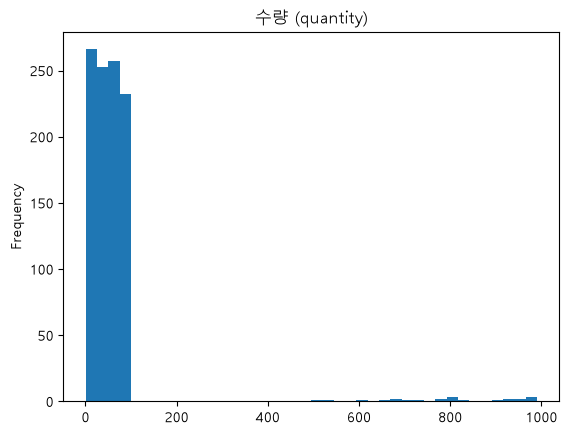

In [15]:
df["quantity"].plot.hist(bins=40, title="수량 (quantity)")
plt.show()

### 어디부터 「튀는 값」 인가 : 박스플롯

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
수염 끝(상한) = 150.0


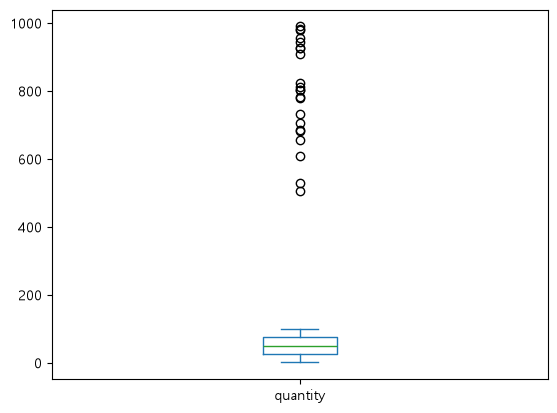

In [16]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1
print("Q1 =", Q1, " Q3 =", Q3, " IQR =", IQR)
print("수염 끝(상한) =", Q3 + 1.5 * IQR)
df["quantity"].plot.box()
plt.show()

### [실습 3] 수량만 그런가

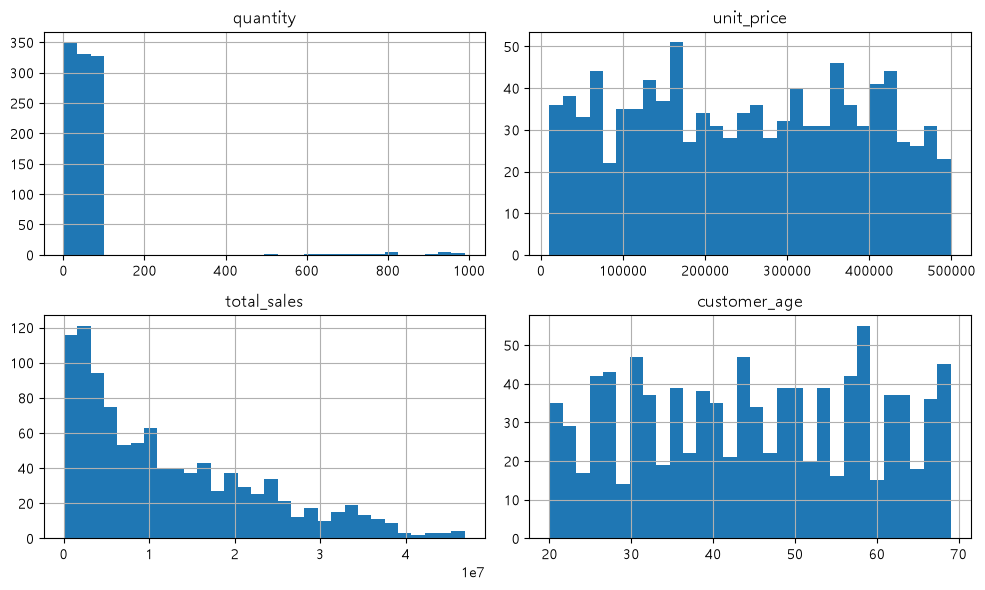

In [17]:
cols = ["quantity", "unit_price",
        "total_sales", "customer_age"]
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

### 4. 전처리 : 빈칸 51 개를 어떻게 할까

In [18]:
dropped = df.dropna(subset=["customer_age"])
print(len(df), "->", len(dropped))

1030 -> 979


### [실습 4] 평균으로 채워 보면

평균 : 44.858
중앙값: 44.858
최빈값: 44.858


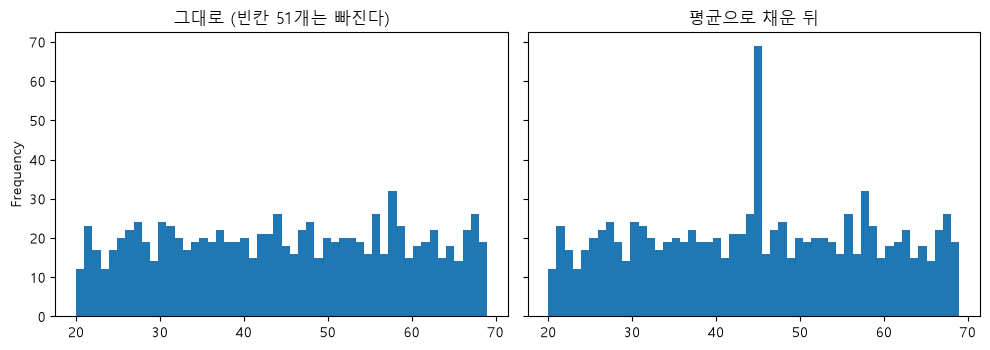

In [19]:
age_mean = df["customer_age"].fillna(df["customer_age"].mean())
print("평균 :", round(age_mean.mean(), 3))
print("중앙값:", round(age_mean.median(), 3))
print("최빈값:", round(age_mean.mode()[0], 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
df["customer_age"].plot.hist(bins=50, ax=ax[0], title="그대로 (빈칸 51개는 빠진다)")
age_mean.plot.hist(bins=50, ax=ax[1], title="평균으로 채운 뒤")
plt.tight_layout()
plt.show()

### 빈칸 결정 마무리, 그리고 중복 제거

In [20]:
# 결정 : 세 칸의 빈칸은 그대로 둔다
print(df["customer_age"].count(), "/", len(df))

979 / 1030


In [21]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


### 22 가 세 번 나왔다

In [22]:
by_iqr  = df["quantity"] > Q3 + 1.5 * IQR     # 통계 규칙 : 26쪽 상한 150 밖
by_rule = df["quantity"] > 100               # 업무 규칙 : 한 주문 100개 넘지 않는다
print("IQR 규칙 :", by_iqr.sum(), " 업무 규칙 :", by_rule.sum(), " 둘이 같은 줄인가 :", (by_iqr == by_rule).all())

IQR 규칙 : 22  업무 규칙 : 22  둘이 같은 줄인가 : True


### 수량이 틀렸나, 금액이 틀렸나

In [23]:
bad = by_rule
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("22건 중 금액이 안 맞는 줄 :", (diff[bad] > 1).sum())
ratio = df["total_sales"] / df["unit_price"]
ratio[bad].round(2).head(6)

22건 중 금액이 안 맞는 줄 : 22


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

### [실습 5] 22 개를 되돌림

In [24]:
df.loc[bad, "quantity"] = ratio[bad].round().astype(int)
calc = df["quantity"] * df["unit_price"]
diff = (df["total_sales"] - calc).abs()
print("수량 최대 :", df["quantity"].max(), " 불일치 :", (diff > 1).sum())

수량 최대 : 99  불일치 : 0


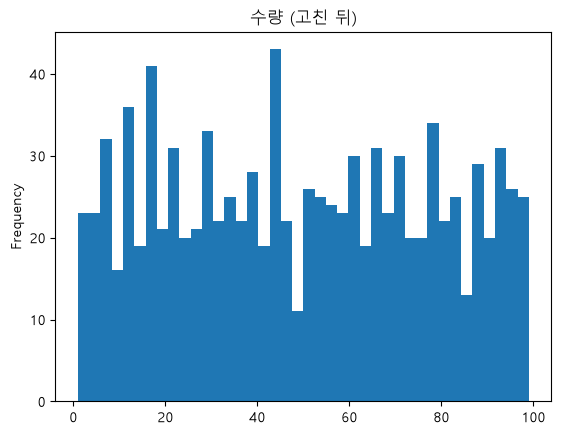

In [25]:
df["quantity"].plot.hist(bins=40, title="수량 (고친 뒤)")
plt.show()

### 고칠 수 없는 것은 표시만, 그리고 저장

In [26]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df["date_error"].value_counts()

date_error
False    857
True     147
Name: count, dtype: int64

In [27]:
df.to_csv("sales_clean.csv", index=False)
df.shape

(1004, 15)

### 여기까지 한 일을 한 표로

| 점검 (1차시) | 처리 | 전 | 후 | 근거 |
|---|---|---|---|---|
| 결측치 51 · 30 · 5 | 유지 | 979 / 1000 / 1025 | 같음 | 대체하면 없던 봉우리 (29쪽) |
| 중복 26 쌍 | 뒤쪽 제거 | 1,030 줄 | 1,004 줄 | 금액 소수점까지 동일 (30쪽) |
| 금액 ≠ 수량 × 단가 22 건 | 수량을 금액 ÷ 단가로 복원 | 최대 990 | 최대 99, 불일치 0 | 나눈 값이 전부 정수 (32쪽) |
| 수량 > 150 22 건 | 위와 같은 줄 | 22 | 0 | 두 규칙이 같은 줄 (31쪽) |
| 도착일 < 배송일 149 건 | date_error 표시 | 없음 | 147 True | 판단 근거 없음 (34쪽) |

### 5. 깨끗해진 데이터에게 묻는다

- Q1 보통 주문은 어떤 것인가 → 한 컬럼을 요약 : 평균 · 중앙값 · 왜도
- Q2 무엇이 매출을 결정하나 → 두 컬럼의 관계 : 산점도 · 상관계수
- Q3 카테고리 · 지역 · 달에 따라 매출이 다른가 → 묶어서 셈 : groupby pivot_table

### Q1 보통 주문은 어떤 것인가

In [28]:
df[["quantity", "unit_price", "total_sales", "customer_age"]].agg(["mean", "median", "skew"]).round(2)

,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02


### 잠깐, 고치기 전에 읽었다면

In [29]:
raw = pd.read_csv("sales_data.csv")                    # 고치기 전 파일을 다시 읽어 비교
print("수량-총액 상관계수 고치기 전 :", round(raw["quantity"].corr(raw["total_sales"]), 2),
      "  고친 뒤 :", round(df["quantity"].corr(df["total_sales"]), 2))

수량-총액 상관계수 고치기 전 : 0.21   고친 뒤 : 0.67


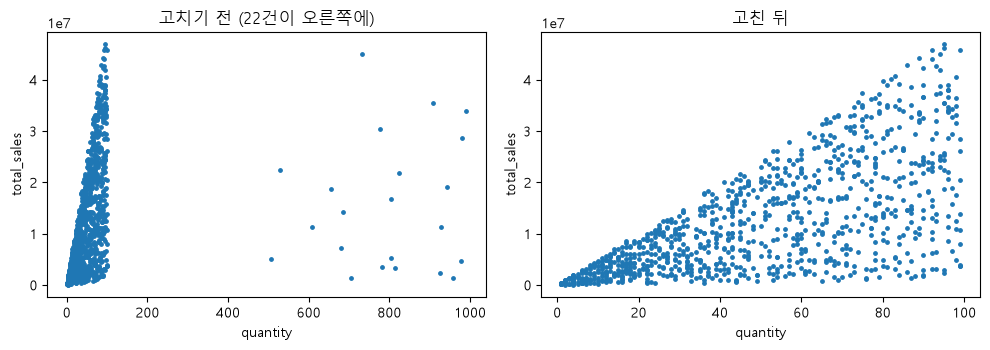

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
raw.plot.scatter(x="quantity", y="total_sales", s=6, ax=ax[0], title="고치기 전 (22건이 오른쪽에)")
df.plot.scatter(x="quantity", y="total_sales", s=6, ax=ax[1], title="고친 뒤")
plt.tight_layout()
plt.show()

### Q2 무엇이 매출을 결정하나

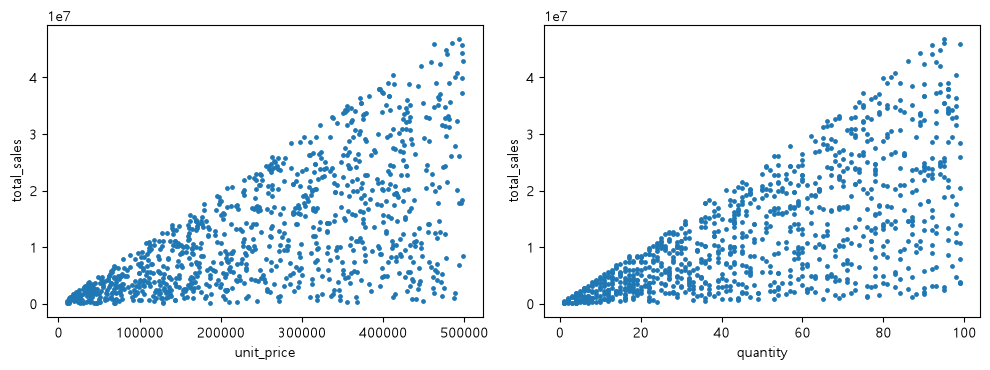

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
df.plot.scatter(x="unit_price", y="total_sales", s=6, ax=ax[0])
df.plot.scatter(x="quantity",   y="total_sales", s=6, ax=ax[1])
plt.tight_layout()
plt.show()

In [32]:
num = ["quantity", "unit_price", "total_sales",
       "customer_age", "satisfaction"]
df[num].corr().round(2)

,quantity,unit_price,total_sales,customer_age,satisfaction
quantity,1.00,0.01,0.67,0.03,0.02
unit_price,0.01,1.00,0.65,-0.07,0.06
total_sales,0.67,0.65,1.00,-0.05,0.06
customer_age,0.03,-0.07,-0.05,1.00,-0.05
satisfaction,0.02,0.06,0.06,-0.05,1.00


### 같은 표를 색으로 : 히트맵

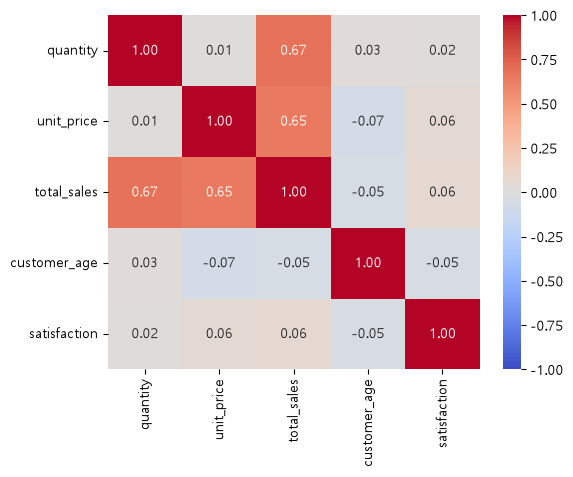

In [33]:
import seaborn as sns
plt.figure(figsize=(6, 4.6))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0,
            vmin=-1, vmax=1)
plt.show()

### Q3 카테고리마다 매출이 다른가

In [34]:
by_cat = df.groupby("category")["total_sales"].sum()
(by_cat / 1e8).round(1)            # 억 원 단위

category
가구      28.4
도서      24.5
식품      25.1
의류      21.8
전자제품    24.7
Name: total_sales, dtype: float64

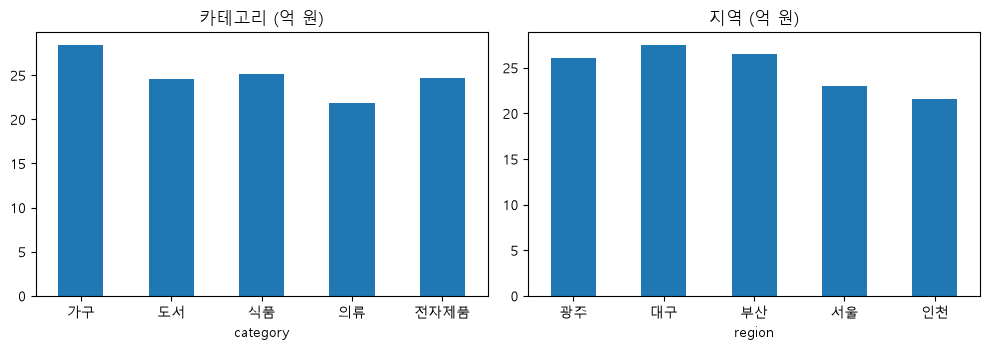

In [35]:
by_reg = df.groupby("region")["total_sales"].sum()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
(by_cat / 1e8).plot.bar(ax=ax[0], title="카테고리 (억 원)", rot=0)
(by_reg / 1e8).plot.bar(ax=ax[1], title="지역 (억 원)", rot=0)
plt.tight_layout()
plt.show()

### [실습 6] 더 잘게 : 지역 × 카테고리, 달별

In [36]:
pv = df.pivot_table(index="region", columns="category",
                    values="total_sales", aggfunc="sum")
(pv / 1e8).round(1)

category,가구,도서,식품,의류,전자제품
region,,,,,
광주,5.1,3.4,5.0,5.4,7.1
대구,7.2,5.0,5.8,4.8,4.7
부산,6.6,5.4,6.8,3.6,4.1
서울,4.4,6.3,3.8,4.2,4.3
인천,5.2,4.3,3.8,3.9,4.4


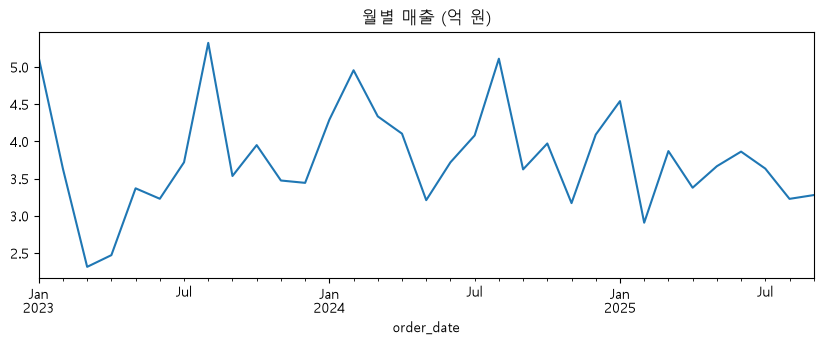

(Period('2023-08', 'M'), np.float64(5.3))

In [37]:
month = df["order_date"].dt.to_period("M")
monthly = df.groupby(month)["total_sales"].sum() / 1e8
monthly.plot(figsize=(10, 3.2), title="월별 매출 (억 원)")
plt.show()
monthly.idxmax(), round(monthly.max(), 1)

### 데이터가 답한 것, 답하지 않은 것

- Q1 보통 주문은 수량 48 개, 943만 원 안팎 (중앙값)
- Q2 매출을 결정하는 것은 단가와 수량 : 상관계수 0.65 · 0.67. 나이 · 만족도는 0.1 이내
- Q3 카테고리 · 지역 · 달에 따른 차이는 작음 : 가구 28.4억 ~ 의류 21.8억
- 이 데이터로 답할 수 없는 것
  - 「왜」 반품했나, 어느 광고가 먹혔나 : 그런 칸이 없음. 없는 칸은 추측하지 않음
  - 내년 매출 : 예측은 7장 (모델링) 의 일